In [1]:
%pylab inline
import fitsio
import treecorr
import numpy as np
import catutil

Populating the interactive namespace from numpy and matplotlib


In [190]:
data=fitsio.read('/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_no_m/WIDE12H_no_m.fits')

In [196]:
dataU=data[data['object_id']==42216990194032655]

In [197]:
dataU['i_hsmshaperegauss_derived_sigma_e']

array([0.05307861])

In [198]:
dataU['i_hsmshaperegauss_derived_rms_e']

array([0.3941625])

In [205]:
dataU['i_cmodel_flux']

array([3412.2007], dtype=float32)

In [199]:
dataU['tract']

array([9599], dtype=int32)

In [201]:
iid=np.argmin(data['i_hsmshaperegauss_derived_sigma_e'])

In [204]:
data['i_cmodel_flux'][iid]/data['i_cmodel_fluxerr'][iid]

11642.451

In [155]:
catFname=   '/gpfs02/work/shirskms/HSCmock/S19A/shape/XMM/mock_nres13_r003_rotmat10_shear_catalog.fits'
dataG   =   fitsio.read(os.path.join(catFname))
ra     =   dataG['ra_mock']
dec    =   dataG['dec_mock']
e1     =   dataG['shear1_sim']
e2     =   dataG['shear2_sim']
print(np.argmin(dataG['shear1_sim']))
ssPro=dataG[np.argmin(dataG['shear1_sim'])]
print(ssPro)
print(ssPro['z_source_mock'])

470433
(8522, 73562, 37480710713400375, 32.821, -5.499942, -1.e+10, -1.e+10, -1.e+10, -1.e+10, -1.e+10, -1.e+10, -1.e+10, -1.e+10, -1.e+10, 0., -1.)
-1.0


In [156]:
dataG.dtype.names

('tract_id',
 'irow_in_original_fits_file',
 'object_id',
 'ra_mock',
 'dec_mock',
 'e1_mock',
 'e2_mock',
 'shear1_sim',
 'shear2_sim',
 'kappa',
 'noise1_int',
 'noise2_int',
 'noise1_mea',
 'noise2_mea',
 'weight',
 'z_source_mock')

In [16]:
def prepareCat(ver):
    if ver==0:
        pass
    elif ver==1:
        catFname='/work/xiangchong.li/work/S16ACatalogs/oguri_mock/mock_mlz_XMM_000.fits'
        dataG   =   fitsio.read(os.path.join(catFname))
        ra     =   dataG['ira']
        dec    =   dataG['idec']
        e1     =   dataG['mock_gamma1']
        e2     =   dataG['mock_gamma2']
    elif ver==2:
        catFname=   '/gpfs02/work/shirskms/HSCmock/S19A/shape/XMM/mock_nres13_r003_rotmat12_shear_catalog.fits'
        dataG   =   fitsio.read(os.path.join(catFname))
        mask   =   np.abs(dataG['shear1_sim'])<10
        dataG  =   dataG[mask]
        ra     =   dataG['ra_mock']
        dec    =   dataG['dec_mock']
        e1     =   dataG['shear1_sim']
        e2     =   dataG['shear2_sim']
    cat    =   treecorr.Catalog(g1=e1,g2=e2,ra=ra,dec=dec, ra_units='deg',dec_units='deg') 
    return cat
corGG1  =   treecorr.GGCorrelation(nbins=30,min_sep=0.281838293,max_sep=354.8133892,sep_units='arcmin')

In [17]:
cat=prepareCat(ver=1)
corGG1.process(cat)
print(corGG.xip)

[4.95267034e-04 5.03640295e-04 4.88019649e-04 4.37979320e-04
 3.96426902e-04 3.36992592e-04 3.02337222e-04 2.44856250e-04
 1.98133612e-04 1.64449866e-04 1.38394693e-04 1.09287780e-04
 8.94752295e-05 7.01075964e-05 5.61449712e-05 4.54391896e-05
 3.74054888e-05 3.04910506e-05 2.47804047e-05 1.94197135e-05
 1.55372391e-05 1.10765980e-05 8.69122146e-06 6.53771377e-06
 4.13043191e-06 2.45513951e-06 2.08390947e-06 1.29666378e-06
 1.51051163e-06 1.14327745e-06]


In [18]:
cat=prepareCat(ver=2)
corGG1.process(cat)
print(corGG.xip)

[4.95267034e-04 5.03640295e-04 4.88019649e-04 4.37979320e-04
 3.96426902e-04 3.36992592e-04 3.02337222e-04 2.44856250e-04
 1.98133612e-04 1.64449866e-04 1.38394693e-04 1.09287780e-04
 8.94752295e-05 7.01075964e-05 5.61449712e-05 4.54391896e-05
 3.74054888e-05 3.04910506e-05 2.47804047e-05 1.94197135e-05
 1.55372391e-05 1.10765980e-05 8.69122146e-06 6.53771377e-06
 4.13043191e-06 2.45513951e-06 2.08390947e-06 1.29666378e-06
 1.51051163e-06 1.14327745e-06]


In [2]:
import gc
fname   =   'mock_nres13_r003_rotmat12_shear_catalog.fits'
dataG   =   []
for fieldname in catutil.field_names:
    catFname=   '/gpfs02/work/shirskms/HSCmock/S19A/shape/%s/%s' %(fieldname,fname)
    data   =   fitsio.read(os.path.join(catFname))
    mask   =   data['z_source_mock']>0.01
    mask   =   mask&(np.abs(data['e1_mock'])<5.)
    data   =   data[mask]
    dataG.append(data)
    del data,mask
    gc.collect()
dataG=np.hstack(dataG)
ra     =   dataG['ra_mock']
dec    =   dataG['dec_mock']
e1     =   dataG['e1_mock']
e2     =   dataG['e2_mock']
cat    =   treecorr.Catalog(g1=e1,g2=e2,ra=ra,dec=dec, ra_units='deg',dec_units='deg') 
corGG  =   treecorr.GGCorrelation(nbins=30,min_sep=0.281838293,max_sep=354.8133892,sep_units='arcmin')
corGG.process(cat)
del dataG,cat
gc.collect()

In [15]:
corGG.xip/(2.*0.812)**2.

array([1.87787799e-04, 1.90962644e-04, 1.85039846e-04, 1.66066317e-04,
       1.50311105e-04, 1.27775711e-04, 1.14635616e-04, 9.28408579e-05,
       7.51252806e-05, 6.23535916e-05, 5.24743887e-05, 4.14380733e-05,
       3.39258526e-05, 2.65823290e-05, 2.12881937e-05, 1.72289388e-05,
       1.41828426e-05, 1.15611314e-05, 9.39585584e-06, 7.36327073e-06,
       5.89117333e-06, 4.19985548e-06, 3.29540477e-06, 2.47887058e-06,
       1.56611416e-06, 9.30902347e-07, 7.90145002e-07, 4.91649190e-07,
       5.72732758e-07, 4.33490502e-07])

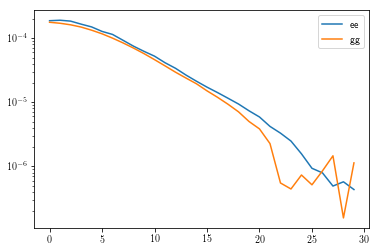

In [22]:
plt.close()
plt.plot(corGG.xip/(2.*0.812)**2.,label='ee')
plt.plot(corGG1.xip,label='gg')
plt.yscale('log')
plt.legend()

In [ ]:
outFname='%s_GGcor.csv' %(ifield)
corGG.write(outFname)

In [216]:
fieldname='WIDE12H'
fname   =   'mock_nres13_r003_rotmat12_shear_catalog.fits'
catFname=   '/gpfs02/work/shirskms/HSCmock/S19A/shape/%s/%s' %(fieldname,fname)
data   =   fitsio.read(os.path.join(catFname))

In [217]:
dataU=data[data['object_id']==42216990194032655]

In [218]:
dataU

array([(9599, 7765, 42216990194032655, 193.2076, 0.2593107, inf, -inf, 0.00407358, 0.00614266, 0.00067369, 0.19506963, 0.8028609, inf, -inf, 0., 0.2657)],
      dtype=[('tract_id', '>i8'), ('irow_in_original_fits_file', '>i8'), ('object_id', '>i8'), ('ra_mock', '>f8'), ('dec_mock', '>f8'), ('e1_mock', '>f4'), ('e2_mock', '>f4'), ('shear1_sim', '>f4'), ('shear2_sim', '>f4'), ('kappa', '>f4'), ('noise1_int', '>f4'), ('noise2_int', '>f4'), ('noise1_mea', '>f4'), ('noise2_mea', '>f4'), ('weight', '>f8'), ('z_source_mock', '>f4')])